<a href="https://colab.research.google.com/github/AyseNil-star/AyseNil-star/blob/main/week07_dynamics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 — Structures Move

**Computational Antibody Engineering**

Every structure in this course so far has been a single set of coordinates. A crystal structure, a
prediction, a complex — each one a still photograph.

Proteins are not still. At 37 °C an antibody is in constant motion: side chains rotate, loops flex,
domains breathe. The single structure you have been analysing is **one frame of a film**, and usually
not a randomly chosen frame — it is the conformation that happened to crystallise.

> **Which parts of an antibody move, how much, and does it matter for anything you have done so far?**

The answer connects back to weeks 4 and 6 in a way that reframes both.

---

### How today works

1. **You run a short simulation** — minimisation and a few picoseconds — so you have touched the
   machinery and know what the pieces are.
2. **You analyse a longer precomputed trajectory** of the same molecule, because a useful simulation
   takes far longer than a class.

**Also due today: your capstone target proposal.** See section 7.

## 0. Setup

We need **OpenMM** (the simulation engine), **PDBFixer** (structure preparation) and **MDTraj**
(trajectory analysis).

In [1]:
%pip install -q openmm pdbfixer mdtraj ImmuneBuilder anarci biopython pandas matplotlib

import warnings
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import mdtraj as mdt
from openmm.app import *
from openmm import *
from openmm.unit import *
from pdbfixer import PDBFixer
import urllib.request, os, time

# Pick the fastest platform available in this runtime.
names = [Platform.getPlatform(i).getName() for i in range(Platform.getNumPlatforms())]
PLATFORM = next(p for p in ["CUDA", "OpenCL", "CPU"] if p in names)
print(f"platforms available: {names}")
print(f"using: {PLATFORM}")
if PLATFORM == "CPU":
    print("\n(No GPU in this runtime. The short run below will take a couple of minutes.\n"
          " Runtime > Change runtime type > GPU makes it much faster, but is not required.)")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
platforms available: ['Reference', 'CPU', 'OpenCL']
using: OpenCL


## 1. What a simulation actually is

Molecular dynamics is a simple idea executed enormously many times:

1. Compute the force on every atom from a **force field** — a parameterised model of bond stretching,
   angle bending, torsions, van der Waals and electrostatics.
2. Move every atom a tiny step according to Newton's laws.
3. Repeat.

The step must be short enough to resolve the fastest motion in the system — bond vibrations — which
forces a timestep of about **2 femtoseconds**. To simulate one microsecond you therefore take **500
million** steps. This is why molecular dynamics is expensive, and why "just simulate it" is rarely the
cheap answer it sounds like.

**Three choices you are making whether or not you think about them:**

| Choice | Ours today | Trade-off |
|---|---|---|
| **Force field** | Amber14 | A model, not physics. Different force fields give measurably different flexibility |
| **Solvent** | implicit (GBn2) | Much faster than explicit water, but weaker at describing surface loops and salt effects |
| **Length** | 10 ns | Long enough to see loop flexibility; **far too short** for large conformational change |

We use implicit solvent so this fits in a class. A publication-quality answer would use explicit water
and run 100× longer. Section 6 makes you check what our shortcut costs.

## 2. Run one yourself

Build a simulation of the trastuzumab Fv — the same molecule from weeks 1, 2 and 4 — and run it briefly.

The preparation steps are as important as the simulation. **PDBFixer** adds hydrogens (absent from most
crystal structures, and about half the atoms in a protein) and repairs missing atoms. Skipping
preparation is one of the most common ways a simulation fails or, worse, quietly produces nonsense.

In [2]:
!apt-get -qq install -y hmmer > /dev/null
!which hmmscan && hmmscan -h | head -2

/usr/bin/hmmscan
# hmmscan :: search sequence(s) against a profile database
# HMMER 3.4 (Aug 2023); http://hmmer.org/


In [3]:
# Predict the Fv from sequence (week 4's tool), so this is self-contained.
from ImmuneBuilder import ABodyBuilder2

VH = ("EVQLVESGGGLVQPGGSLRLSCAASGFNIKDTYIHWVRQAPGKGLEWVARIYPTNGYTRYADSVKG"
      "RFTISADTSKNTAYLQMNSLRAEDTAVYYCSRWGGDGFYAMDYWGQGTLVTVSS")
VL = ("DIQMTQSPSSLSASVGDRVTITCRASQDVNTAVAWYQQKPGKAPKLLIYSASFLYSGVPSRFSGSR"
      "SGTDFTLTISSLQPEDFATYYCQQHYTTPPTFGQGTKVEIK")

if not os.path.exists("fv_pred.pdb"):
    ABodyBuilder2().predict({"H": VH, "L": VL}).save("fv_pred.pdb")

fixer = PDBFixer(filename="fv_pred.pdb")
fixer.findMissingResidues()
fixer.findMissingAtoms()
fixer.addMissingAtoms()
fixer.addMissingHydrogens(7.0)          # pH 7
PDBFile.writeFile(fixer.topology, fixer.positions, open("fv_ready.pdb", "w"))

# NB: openmm.unit's star-import shadows the builtin sum(), so use len() here.
n_heavy = len([a for a in fixer.topology.atoms() if a.element.symbol != "H"])
print(f"atoms after preparation: {fixer.topology.getNumAtoms()}")
print(f"   heavy atoms: {n_heavy}")
print(f"   hydrogens added: {fixer.topology.getNumAtoms() - n_heavy}")
print("\nNote how many atoms were invisible to every analysis you have done so far.")

atoms after preparation: 3439
   heavy atoms: 1753
   hydrogens added: 1686

Note how many atoms were invisible to every analysis you have done so far.


In [4]:
pdb = PDBFile("fv_ready.pdb")
forcefield = ForceField("amber14-all.xml", "implicit/gbn2.xml")
system = forcefield.createSystem(pdb.topology,
                                 nonbondedMethod=CutoffNonPeriodic,
                                 nonbondedCutoff=2.0 * nanometer,
                                 constraints=HBonds)      # freeze X-H bonds -> 2 fs steps

integrator = LangevinMiddleIntegrator(300 * kelvin,        # body temperature-ish
                                      1 / picosecond,      # coupling to the heat bath
                                      0.002 * picoseconds) # 2 fs timestep

sim = Simulation(pdb.topology, system, integrator, Platform.getPlatformByName(PLATFORM))
sim.context.setPositions(pdb.positions)

e0 = sim.context.getState(getEnergy=True).getPotentialEnergy()
print(f"energy before minimisation: {e0.value_in_unit(kilojoule_per_mole):>12.0f} kJ/mol")

t = time.time()
sim.minimizeEnergy(maxIterations=200)
e1 = sim.context.getState(getEnergy=True).getPotentialEnergy()
print(f"energy after minimisation:  {e1.value_in_unit(kilojoule_per_mole):>12.0f} kJ/mol"
      f"   ({time.time() - t:.0f} s)")
print("\nMinimisation removes clashes and strain. It is not dynamics - nothing has moved yet.")

energy before minimisation:       -34129 kJ/mol
energy after minimisation:        -34753 kJ/mol   (1 s)

Minimisation removes clashes and strain. It is not dynamics - nothing has moved yet.


In [5]:
# Now actual dynamics: give the atoms velocities and let them move.
sim.context.setVelocitiesToTemperature(300 * kelvin)

STEPS = 500 if PLATFORM == "CPU" else 5000      # 1 ps on CPU, 10 ps on a GPU
t = time.time()
sim.step(STEPS)
elapsed = time.time() - t

simulated_ps = STEPS * 0.002
rate = simulated_ps / elapsed * 60
print(f"simulated {simulated_ps:.0f} ps in {elapsed:.0f} s   ->   {rate:.1f} ps/min")
print(f"at this rate, 100 ns would take {100_000 / rate / 60 / 24:.1f} days")
print("\nThat is why the trajectory you are about to analyse was computed in advance.")

simulated 10 ps in 1 s   ->   586.3 ps/min
at this rate, 100 ns would take 0.1 days

That is why the trajectory you are about to analyse was computed in advance.


### That last number is the point of this section

You have now run a real molecular dynamics simulation. You have also discovered that the useful length
scale is out of reach in a classroom, and on a CPU is out of reach entirely.

This is the honest economics of the method: **MD is the most expensive tool in this course by orders of
magnitude.** Every later decision about whether to run it is really a decision about whether the
question justifies the cost.

## 3. A longer trajectory

Now analyse a **10 ns** simulation of the same Fv, under the same conditions as section 2.

The next cell runs it. At the speed you measured above that is roughly **20 minutes on a Colab GPU**
(the cell prints its own estimate and a progress line every nanosecond). If you already have
`fv_ca.dcd` and `fv_ca_topology.pdb` from an earlier session, upload them first and the cell skips
the run. Colab deletes session files when the runtime disconnects, so download both files once the
run finishes if you want to reuse them.

To keep the file small it saves **α-carbons only** — one atom per residue. That is enough for
backbone flexibility, which is what we want, though it discards all side-chain motion.

In [6]:
# Generate the 10 ns C-alpha trajectory analysed in sections 3-6.
# Same physics as section 2: Amber14 + GBn2 implicit solvent, 300 K, 2 fs Langevin steps.
# Skipped if both files already exist (e.g. a precomputed copy you uploaded).
import gc

TOTAL_NS  = 10          # length of the run
FRAME_PS  = 10          # save one frame every 10 ps  ->  1000 frames
REPORT_NS = 1           # print progress every 1 ns
DT_PS     = 0.002       # 2 fs, as in section 2
SEED      = 2026        # fixed seed so the run is reproducible

STEPS_PER_FRAME = int(round(FRAME_PS / DT_PS))             # 5,000
N_STEPS         = int(round(TOTAL_NS * 1000 / DT_PS))      # 5,000,000
CHUNK           = int(round(REPORT_NS * 1000 / DT_PS))     # 500,000

if os.path.exists("fv_ca.dcd") and os.path.exists("fv_ca_topology.pdb"):
    print("fv_ca.dcd and fv_ca_topology.pdb already exist - skipping the simulation.")
else:
    print(f"Estimated time at the rate measured in section 2: "
          f"~{TOTAL_NS * 1000 / rate:.0f} min on {PLATFORM}")
    if PLATFORM == "CPU":
        raise RuntimeError("A 10 ns run on CPU would take days. Switch to a GPU runtime "
                           "(Runtime > Change runtime type), or upload a precomputed "
                           "fv_ca.dcd and fv_ca_topology.pdb and re-run this cell.")

    # C-alpha atoms only: one per residue, in the same order as fv_ready.pdb
    ca_idx = [a.index for a in pdb.topology.atoms() if a.name == "CA"]
    md_top = mdt.Topology.from_openmm(pdb.topology)

    # Fresh simulation from the prepared structure (the section 2 run is left untouched)
    md_integrator = LangevinMiddleIntegrator(300 * kelvin, 1 / picosecond, DT_PS * picoseconds)
    md_integrator.setRandomNumberSeed(SEED)
    md_sim = Simulation(pdb.topology, system, md_integrator, Platform.getPlatformByName(PLATFORM))
    md_sim.context.setPositions(pdb.positions)
    md_sim.minimizeEnergy(maxIterations=1000)                # longer than section 2's 200
    md_sim.context.setVelocitiesToTemperature(300 * kelvin, SEED)

    # Write to temporary names, renamed only once the run finishes, so an interrupted
    # run can never leave behind a half-length file that this cell would then skip.
    try:
        dcd = DCDReporter("fv_ca.partial.dcd", STEPS_PER_FRAME, atomSubset=ca_idx)
        sliced_later = False
    except TypeError:                                        # older OpenMM: no atomSubset
        dcd = DCDReporter("fv_full.partial.dcd", STEPS_PER_FRAME)
        sliced_later = True
    md_sim.reporters.append(dcd)
    md_sim.reporters.append(StateDataReporter("fv_md_log.csv", STEPS_PER_FRAME,
                                              step=True, time=True, potentialEnergy=True,
                                              temperature=True, speed=True))

    t0 = time.time()
    for i in range(N_STEPS // CHUNK):
        md_sim.step(CHUNK)
        done = (i + 1) * CHUNK * DT_PS / 1000                # ns completed
        el = time.time() - t0
        print(f"  {done:5.1f} / {TOTAL_NS} ns   elapsed {el / 60:5.1f} min   "
              f"remaining ~{el / done * (TOTAL_NS - done) / 60:5.1f} min", flush=True)

    # Close the trajectory file before using it
    md_sim.reporters.clear()
    del dcd
    gc.collect()

    if sliced_later:
        (mdt.load("fv_full.partial.dcd", top=md_top).atom_slice(ca_idx)
            .save_dcd("fv_ca.partial.dcd"))
        os.remove("fv_full.partial.dcd")
    os.replace("fv_ca.partial.dcd", "fv_ca.dcd")

    # Topology: the C-alpha atoms of the prepared, minimised structure
    xyz = md_sim.context.getState(getPositions=True).getPositions(asNumpy=True)
    (mdt.Trajectory(xyz.value_in_unit(nanometer)[None], md_top)
        .atom_slice(ca_idx).save_pdb("fv_ca_topology.pdb"))

    print(f"\ndone in {(time.time() - t0) / 60:.1f} min")
    check = mdt.load("fv_ca.dcd", top="fv_ca_topology.pdb")
    print(f"wrote fv_ca.dcd ({check.n_frames} frames, {check.n_atoms} C-alpha atoms) "
          f"and fv_ca_topology.pdb; energies and temperature in fv_md_log.csv")

Estimated time at the rate measured in section 2: ~17 min on OpenCL
    1.0 / 10 ns   elapsed   1.7 min   remaining ~ 15.0 min
    2.0 / 10 ns   elapsed   3.3 min   remaining ~ 13.1 min
    3.0 / 10 ns   elapsed   4.9 min   remaining ~ 11.4 min
    4.0 / 10 ns   elapsed   6.5 min   remaining ~  9.8 min
    5.0 / 10 ns   elapsed   8.1 min   remaining ~  8.1 min
    6.0 / 10 ns   elapsed   9.7 min   remaining ~  6.5 min
    7.0 / 10 ns   elapsed  11.3 min   remaining ~  4.9 min
    8.0 / 10 ns   elapsed  13.0 min   remaining ~  3.2 min
    9.0 / 10 ns   elapsed  14.6 min   remaining ~  1.6 min
   10.0 / 10 ns   elapsed  16.2 min   remaining ~  0.0 min

done in 16.2 min
wrote fv_ca.dcd (1000 frames, 227 C-alpha atoms) and fv_ca_topology.pdb; energies and temperature in fv_md_log.csv


In [7]:
for fname in ["fv_ca.dcd", "fv_ca_topology.pdb"]:
    if not os.path.exists(fname):
        raise FileNotFoundError(f"{fname} not found - run the simulation cell above, "
                                "or upload a precomputed copy to this session.")

traj = mdt.load("fv_ca.dcd", top="fv_ca_topology.pdb")
print(traj)
print(f"\nframes: {traj.n_frames}")
print(f"atoms:  {traj.n_atoms} (one per residue)")
print(f"spacing: {10000 / traj.n_frames:.0f} ps between frames")

# Chain 0 is the heavy chain, chain 1 the light chain.
for c in traj.topology.chains:
    nums = [r.resSeq for r in c.residues]
    print(f"chain {c.index}: {len(nums)} residues, numbered {min(nums)}-{max(nums)}")

<mdtraj.Trajectory with 1000 frames, 227 atoms, 227 residues, without unitcells>

frames: 1000
atoms:  227 (one per residue)
spacing: 10 ps between frames
chain 0: 120 residues, numbered 1-120
chain 1: 107 residues, numbered 1-107


### Careful — the numbering has been overwritten

Look at those residue numbers: they run **contiguously** from 1. But ABodyBuilder2 wrote this structure
with **IMGT** numbering, which is sparse — IMGT reserves positions, so a real IMGT-numbered heavy chain
has gaps and runs past 128.

**PDBFixer silently renumbered the residues sequentially** when it prepared the structure for simulation.
Nothing warned us. If you now assume `resSeq` is an IMGT position and look up "IMGT 105-117" for CDR-H3,
you will select the wrong residues and every conclusion downstream will be wrong — plausibly wrong,
which is the dangerous kind.

This is the fourth numbering trap of the course, after antibody schemes (week 2), crystal copies
(week 3) and construct versus full-length numbering (week 5). The fix is the same every time: **derive
the numbering from the sequence** rather than trusting whatever integers a file happens to carry.

In [8]:
from anarci import number

THREE_TO_ONE = {"ALA":"A","ARG":"R","ASN":"N","ASP":"D","CYS":"C","GLN":"Q","GLU":"E",
                "GLY":"G","HIS":"H","ILE":"I","LEU":"L","LYS":"K","MET":"M","PHE":"F",
                "PRO":"P","SER":"S","THR":"T","TRP":"W","TYR":"Y","VAL":"V"}

imgt_positions = {}          # chain index -> [IMGT position per residue, in order]
for c in traj.topology.chains:
    seq = "".join(THREE_TO_ONE.get(r.name, "X") for r in c.residues)
    numbering, chain_type = number(seq, scheme="imgt")
    occupied = [p for (p, ic), a in numbering if a != "-"]
    imgt_positions[c.index] = occupied
    print(f"chain {c.index}: ANARCI calls it type {chain_type}, "
          f"{len(occupied)} positions, highest IMGT number {max(occupied)}")

print("\nThe highest IMGT number exceeds the residue count - which is how you can tell")
print("the file numbering was not IMGT.")

chain 0: ANARCI calls it type H, 120 positions, highest IMGT number 128
chain 1: ANARCI calls it type L, 107 positions, highest IMGT number 127

The highest IMGT number exceeds the residue count - which is how you can tell
the file numbering was not IMGT.


## 4. RMSD and RMSF — two different questions

These sound alike and answer opposite questions.

**RMSD** (root-mean-square *deviation*) compares the whole structure to a reference, frame by frame. It
is a function of **time** and tells you whether the simulation has settled.

**RMSF** (root-mean-square *fluctuation*) measures how much each residue moves about its own average
position over the run. It is a function of **residue** and tells you *where* the flexibility is.

RMSD first: has the simulation equilibrated?

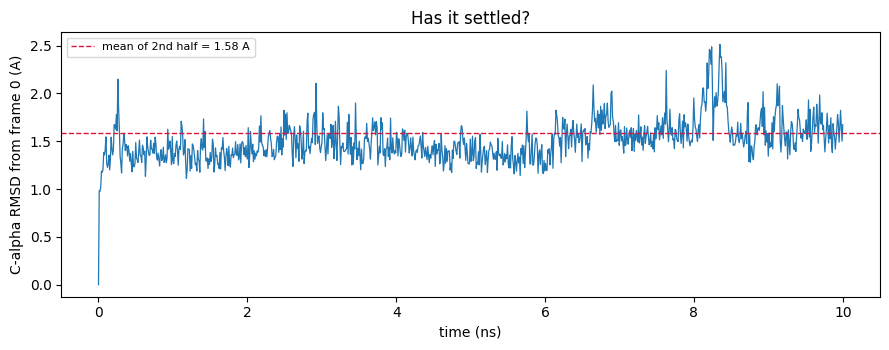

RMSD first 1 ns:  1.37 A
RMSD last 5 ns:   1.58 A
drift between them: +0.21 A


In [9]:
traj.superpose(traj, 0)                      # align every frame to the first
rmsd = mdt.rmsd(traj, traj, 0) * 10          # nm -> angstrom
time_ns = np.linspace(0, 10, traj.n_frames)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(time_ns, rmsd, lw=0.9)
ax.axhline(rmsd[len(rmsd) // 2:].mean(), color="crimson", ls="--", lw=1,
           label=f"mean of 2nd half = {rmsd[len(rmsd)//2:].mean():.2f} A")
ax.set_xlabel("time (ns)"); ax.set_ylabel("C-alpha RMSD from frame 0 (A)")
ax.set_title("Has it settled?")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"RMSD first 1 ns:  {rmsd[time_ns < 1].mean():.2f} A")
print(f"RMSD last 5 ns:   {rmsd[time_ns > 5].mean():.2f} A")
print(f"drift between them: {rmsd[time_ns > 5].mean() - rmsd[time_ns < 1].mean():+.2f} A")

The structure moves away from its starting point and then fluctuates around a new average. The early
rise is **equilibration** — the model relaxing out of the predicted starting conformation — and it is
not data. Conventionally you discard it and analyse only what follows.

Now the question we actually care about: **where** is the motion?

In [10]:
EQUIL_NS = 2.0                                   # discard the first 2 ns
production = traj[time_ns >= EQUIL_NS]
production.superpose(production, 0)

rmsf = mdt.rmsf(production, production, 0) * 10  # nm -> angstrom

IMGT_CDR = {"CDR1": (27, 38), "CDR2": (56, 65), "CDR3": (105, 117)}


def region_of(prefix, imgt):
    for name, (lo, hi) in IMGT_CDR.items():
        if lo <= imgt <= hi:
            return f"{prefix}-{name}"
    return "framework"


rows, k = [], 0
for c in production.topology.chains:
    prefix = "H" if c.index == 0 else "L"
    for j, r in enumerate(c.residues):
        p = imgt_positions[c.index][j]          # the TRUE IMGT position
        rows.append({"chain": prefix, "imgt": p,
                     "region": region_of(prefix, p), "rmsf": rmsf[k]})
        k += 1

flex = pd.DataFrame(rows)

print(f"analysed {len(production)} frames ({EQUIL_NS}-10 ns)\n")
summary = flex.groupby("region").rmsf.agg(["mean", "max", "count"]).round(2)
print(summary.sort_values("mean", ascending=False).to_string())

analysed 800 frames (2.0-10 ns)

           mean   max  count
region                      
H-CDR1     1.03  1.45      8
H-CDR2     0.96  1.36      8
L-CDR1     0.95  1.36      6
framework  0.89  2.85    180
L-CDR2     0.89  1.04      3
H-CDR3     0.84  1.52     13
L-CDR3     0.63  0.77      9


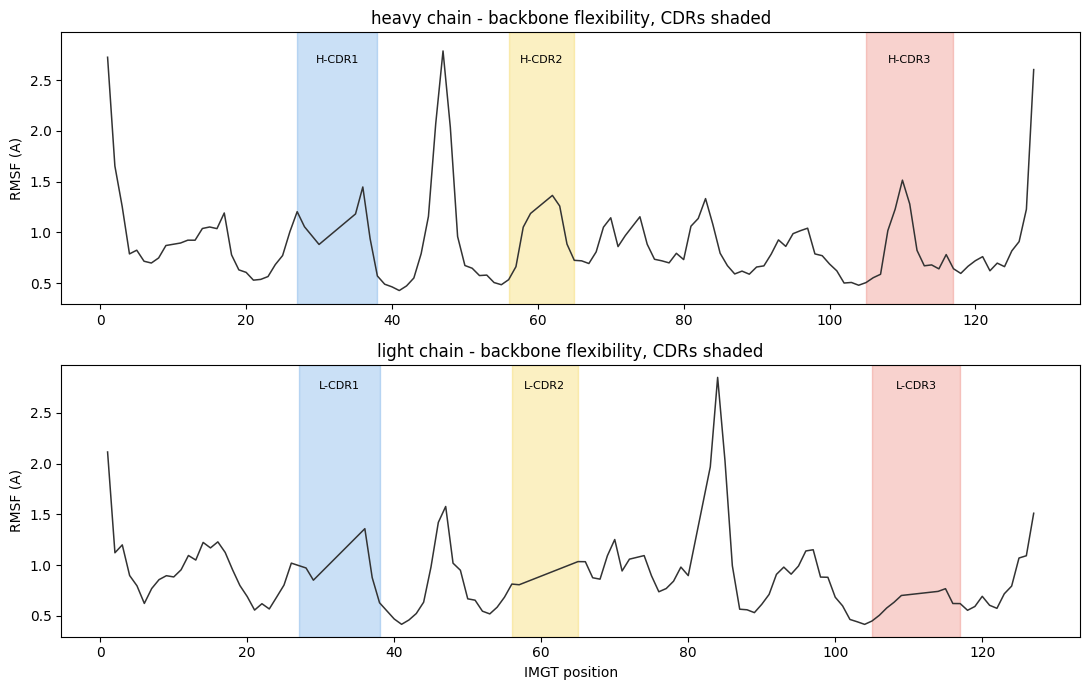

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharey=True)
colours = {"CDR1": "#2E86DE", "CDR2": "#F1C40F", "CDR3": "#E74C3C"}

for ax, ch, label in zip(axes, ["H", "L"], ["heavy chain", "light chain"]):
    sub = flex[flex.chain == ch]
    ax.plot(sub.imgt, sub.rmsf, color="#333", lw=1.1)
    for name, (lo, hi) in IMGT_CDR.items():
        ax.axvspan(lo, hi, color=colours[name], alpha=0.25)
        ax.text((lo + hi) / 2, ax.get_ylim()[1] * 0.92, f"{ch}-{name}",
                ha="center", fontsize=8)
    ax.set_ylabel("RMSF (A)")
    ax.set_title(f"{label} - backbone flexibility, CDRs shaded")
axes[1].set_xlabel("IMGT position")
plt.tight_layout(); plt.show()

### YOUR TURN — Question 1

From the table and the plots:

1. Rank the six CDRs by mean RMSF, and compare them to the framework mean. Is the difference large or
   modest?

   
2. Find the **single most flexible residues** in the whole molecule. Are they in CDRs? Where are they,
   and what is special about their position in the chain? (This one is an artefact — say why.)
3. Weeks 2 and 4 both singled out CDR-H3: the loop with no canonical conformations and the
   worst-predicted region. Is it the most flexible loop here? If not, name what tops it and say by how
   much.
4. Heavy-chain CDRs and light-chain CDRs behave differently in this run. Which set moves more, and does
   that fit what you know about how the two chains are generated?

1. H-CDR2, H-CDR1, H-CDR3, L-CDR1, L-CDR2, and L-CDR3.   The difference between the CDRs and the rest of the framework is modest (the peaks are slightly higher, but not drastically different)
2. They are not in the CDRs.   They are at the very beginning (N-terminus) and very end (C-terminus) of the chains.   Why it's an artefact: The ends of the protein chain flap around freely in simulations because they lack neighboring atoms on one side to hold them in place.
3. No, it is not.   H-CDR2 and H-CDR1 both move more overall. H-CDR2 has a higher average flexibility than H-CDR3 by about 0.25.
4. Heavy-chain CDRs move more than light-chain CDRs.   Does it fit? Yes, because heavy chains are generated through more complex genetic recombination (V(D)J), which naturally builds in more diversity and structural flexibility.   

### Two things in that table deserve comment

**The CDR/framework difference is real but modest.** CDR loops move more than the framework on average,
but not dramatically so. If you expected the CDRs to stand out as obviously floppy against a rigid
scaffold, the data is more sober than that. An Fv is a tightly packed beta-sandwich and the loops are
anchored at both ends.

**The most mobile residues are not CDRs at all — they are the chain termini**, and that is an
**artefact of our construct**. We simulated an isolated Fv. In a real antibody those termini are not
free: the heavy chain continues into CH1 and the light chain into CL. We cut the molecule in half and
the cut ends flap. Any analysis that ranked residues by raw flexibility would put this artefact at the
top of the list.

That is worth generalising. **A simulation faithfully reports the dynamics of the system you actually
built, not of the molecule you meant to study.** Truncations, missing partners, missing glycans and
missing ions all show up as motion that looks like biology.

**On CDR-H3 specifically.** Weeks 2 and 4 both pointed at CDR-H3 as the problem region, so it is
reasonable to expect it to dominate here. It does not obviously do so. Three honest reasons, and we
cannot separate them from this data alone: trastuzumab's CDR-H3 is short (11 residues) and unusually
well-packed against the framework; 10 ns is short; and implicit solvent tends to under-represent loop
motion. Do not let the expectation overwrite the measurement — but do not conclude from one antibody
and one short run that the expectation is wrong either.

## 5. The payoff — flexibility and predictability

Here is the question worth asking today.

In **week 4** you measured how wrong ABodyBuilder2's prediction of this exact antibody was, per residue.
Today you measured how much each residue **moves**.

If those two quantities are related, it changes how you interpret prediction error. A model that places
a rigid residue wrongly has simply made a mistake. A model that places a *mobile* residue wrongly may be
facing a question with no single correct answer — the residue does not have one position to predict.

Let's test it.

In [12]:
# Regenerate week 4's per-residue benchmark for trastuzumab, if it is not here already.
#   pred_err   = ABodyBuilder2's own per-residue error estimate (A). ImmuneBuilder writes it
#                into the B-factor column of the file it saves, so fv_pred.pdb already has it.
#   actual_err = C-alpha distance (A) between that prediction and the 1N8Z crystal structure,
#                after superposing the two Fvs on their framework C-alphas.
# Residues are matched by sequence alignment, not by residue number: the prediction carries
# IMGT numbers, the crystal file carries its own (see section 3 for why that matters).
from Bio.PDB import PDBParser, Superimposer
from Bio.Align import PairwiseAligner, substitution_matrices
from Bio.SeqUtils import seq1

CSV = "wk4_trastuzumab_per_residue.csv"
CRYSTAL = "1N8Z"                                   # trastuzumab Fab bound to HER2
IMGT_CDR_RANGES = [(27, 38), (56, 65), (105, 117)]

if os.path.exists(CSV):
    print(f"{CSV} already exists - delete it to regenerate.")
else:
    if not os.path.exists(f"{CRYSTAL}.pdb"):
        urllib.request.urlretrieve(f"https://files.rcsb.org/download/{CRYSTAL}.pdb",
                                   f"{CRYSTAL}.pdb")
    bp = PDBParser(QUIET=True)
    pred = bp.get_structure("pred", "fv_pred.pdb")[0]          # chains H and L, IMGT numbered
    crys = bp.get_structure("crys", f"{CRYSTAL}.pdb")[0]

    def protein_residues(chain):
        return [r for r in chain if r.id[0] == " " and "CA" in r]

    def seq_of(residues):
        return "".join(seq1(r.get_resname()) for r in residues)

    aligner = PairwiseAligner()
    aligner.mode = "local"                          # the crystal chains also hold CH1 / CL
    aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
    aligner.open_gap_score, aligner.extend_gap_score = -10, -0.5

    crys_chains = {c.id: protein_residues(c) for c in crys if len(protein_residues(c)) > 0}
    rows, pred_ca, crys_ca = [], [], []
    for pc in ["H", "L"]:
        p_res = protein_residues(pred[pc])
        p_seq = seq_of(p_res)
        # Pick the crystal chain that matches this predicted chain best - never assume chain IDs
        best = max(crys_chains, key=lambda cid: aligner.score(p_seq, seq_of(crys_chains[cid])))
        c_res = crys_chains[best]
        c_seq = seq_of(c_res)
        aln = aligner.align(p_seq, c_seq)[0]
        n_before = len(rows)
        for (ps, pe), (cs, ce) in zip(*aln.aligned):
            for i, j in zip(range(ps, pe), range(cs, ce)):
                if p_seq[i] != c_seq[j]:
                    continue                        # compare identical residues only
                pr = p_res[i]
                rows.append({"chain": pc, "imgt": pr.id[1], "ins": pr.id[2].strip(),
                             "aa": p_seq[i], "pred_err": round(float(pr["CA"].get_bfactor()), 3)})
                pred_ca.append(pr["CA"])
                crys_ca.append(c_res[j]["CA"])
        print(f"predicted {pc} -> crystal chain {best}: "
              f"{len(rows) - n_before} of {len(p_res)} residues matched")

    bench = pd.DataFrame(rows)
    framework = ~np.zeros(len(bench), bool)
    for lo, hi in IMGT_CDR_RANGES:
        framework &= ~bench.imgt.between(lo, hi).to_numpy()

    sup = Superimposer()
    sup.set_atoms([a for a, f in zip(crys_ca, framework) if f],
                  [a for a, f in zip(pred_ca, framework) if f])
    rot, tran = sup.rotran                          # Biopython convention: x @ rot + tran
    P = np.array([a.coord for a in pred_ca]) @ rot + tran
    C = np.array([a.coord for a in crys_ca])
    bench["actual_err"] = np.round(np.linalg.norm(P - C, axis=1), 3)

    if bench.duplicated(["chain", "imgt"]).any():
        print("WARNING: IMGT insertion codes present - (chain, imgt) is not unique, "
              "so the merge in the next cell would duplicate rows. Merge on 'ins' as well.")

    bench.to_csv(CSV, index=False)

    def rms(x):
        return float(np.sqrt(np.mean(np.square(x))))

    h3 = (bench.chain == "H") & bench.imgt.between(105, 117)
    print(f"\nwrote {CSV}: {len(bench)} residues")
    print(f"   framework C-alpha RMSD (superposition): {sup.rms:.2f} A")
    print(f"   whole-Fv C-alpha RMSD:                  {rms(bench.actual_err):.2f} A")
    print(f"   CDR-H3 C-alpha RMSD:                    {rms(bench.actual_err[h3]):.2f} A")
    print(f"   predicted vs actual error:  r = {np.corrcoef(bench.pred_err, bench.actual_err)[0, 1]:.2f}")

predicted H -> crystal chain B: 120 of 120 residues matched
predicted L -> crystal chain A: 107 of 107 residues matched

wrote wk4_trastuzumab_per_residue.csv: 227 residues
   framework C-alpha RMSD (superposition): 0.39 A
   whole-Fv C-alpha RMSD:                  0.45 A
   CDR-H3 C-alpha RMSD:                    0.87 A
   predicted vs actual error:  r = 0.52


227 residues matched between the trajectory and week 4's benchmark


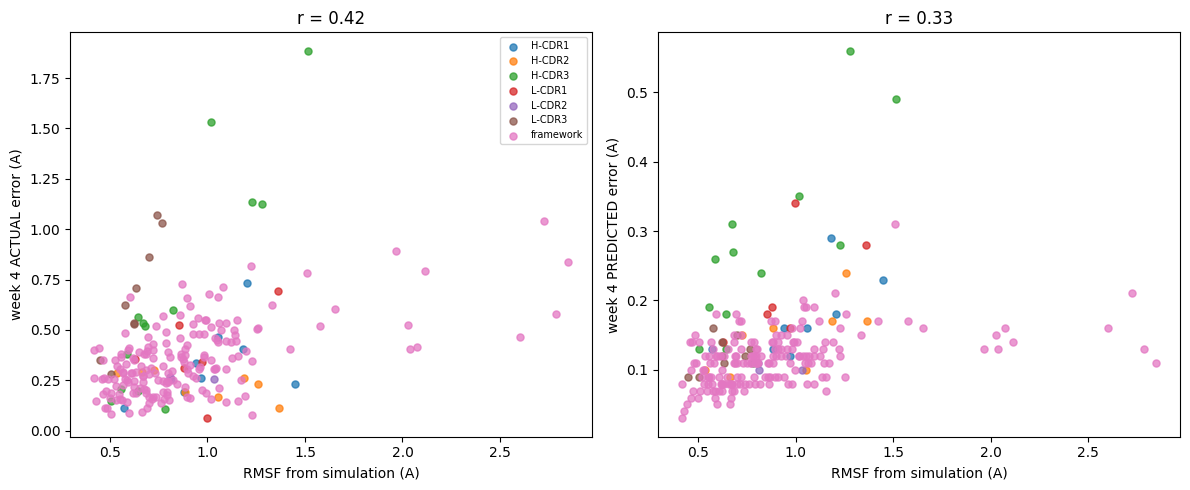

RMSF vs week-4 ACTUAL prediction error:    r = 0.419
RMSF vs week-4 PREDICTED (model) error:    r = 0.332


In [13]:
URL = ("https://raw.githubusercontent.com/USER/REPO/main/week07/data/"
       "wk4_trastuzumab_per_residue.csv")
if not os.path.exists("wk4_trastuzumab_per_residue.csv"):
    try:
        urllib.request.urlretrieve(URL, "wk4_trastuzumab_per_residue.csv")
    except Exception:
        print("Upload wk4_trastuzumab_per_residue.csv, or regenerate it with week 4's notebook.")

wk4 = pd.read_csv("wk4_trastuzumab_per_residue.csv")
merged = flex.merge(wk4[["chain", "imgt", "pred_err", "actual_err"]],
                    on=["chain", "imgt"], how="inner")
print(f"{len(merged)} residues matched between the trajectory and week 4's benchmark")

r_actual = np.corrcoef(merged.rmsf, merged.actual_err)[0, 1]
r_pred = np.corrcoef(merged.rmsf, merged.pred_err)[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, col, lab, r in [(axes[0], "actual_err", "week 4 ACTUAL error (A)", r_actual),
                        (axes[1], "pred_err", "week 4 PREDICTED error (A)", r_pred)]:
    for reg, grp in merged.groupby("region"):
        ax.scatter(grp.rmsf, grp[col], s=26, alpha=0.75, label=reg)
    ax.set_xlabel("RMSF from simulation (A)")
    ax.set_ylabel(lab)
    ax.set_title(f"r = {r:.2f}")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f"RMSF vs week-4 ACTUAL prediction error:    r = {r_actual:.3f}")
print(f"RMSF vs week-4 PREDICTED (model) error:    r = {r_pred:.3f}")

### Interpreting the correlation

Both relationships are positive and moderate: **residues that move more are, on average, residues the
predictor gets more wrong** — and they are also residues the predictor *says* it is less sure about.

Moderate is the right word. This is a real trend across 227 residues, not a tight relationship. Plenty
of mobile residues are predicted well and plenty of rigid ones are predicted badly. Flexibility is one
contributor to prediction difficulty, not the whole story.

Read that carefully, because it admits two explanations and the data here cannot separate them:

1. **Flexible regions are intrinsically hard to predict** — they have no single native conformation, so
   any single predicted structure must be wrong about some of the ensemble.
2. **Flexible regions are poorly determined in the crystal too** — mobile loops give weaker density,
   so the "ground truth" we measured against in week 4 is itself less certain there.

Both are true to some degree, they reinforce each other, and nothing in this notebook separates them.
Be careful not to state the causal version — "flexible regions are hard to predict *because* they are
flexible" — as though you had shown it. You have shown a correlation and offered two explanations.

What you can say safely: **the mobile parts of an antibody and the badly-predicted parts overlap**, so a
single predicted structure is a weaker description of a loop than it is of the framework. For a mobile
region, "the prediction is wrong" may be the wrong complaint — there may be no single right answer for
it to find.

That also puts week 6 in context. The interface that co-folding struggles with is built from loops, and
loops are where both the motion and the prediction error concentrate.

## 6. Is 10 ns enough?

No. But "no" is not a useful answer on its own — the useful question is *how would you know?*

The standard check is to split the trajectory and compare. If the second half tells the same story as
the first, the quantity you are measuring has converged. If it does not, your run is too short and any
number you quote is an artefact of where you stopped.

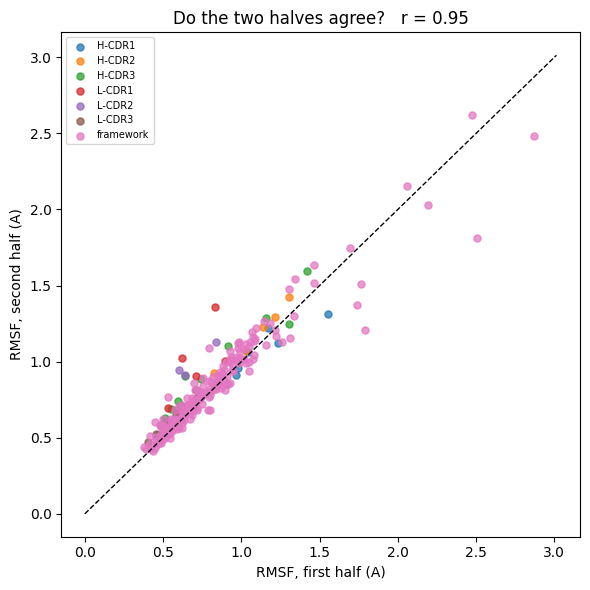

correlation between halves: r = 0.948

Residues where the two halves disagree most:
chain  imgt    region  rmsf_first  rmsf_second
    L    84 framework        2.50         1.81
    L    85 framework        1.79         1.21
    L    36    L-CDR1        0.83         1.36
    L    37    L-CDR1        0.62         1.02
    H     1 framework        2.87         2.48
    L    83 framework        1.74         1.37


In [14]:
half = len(production) // 2
first, second = production[:half], production[half:]
first.superpose(first, 0); second.superpose(second, 0)

flex["rmsf_first"] = mdt.rmsf(first, first, 0) * 10
flex["rmsf_second"] = mdt.rmsf(second, second, 0) * 10
r_halves = np.corrcoef(flex.rmsf_first, flex.rmsf_second)[0, 1]

fig, ax = plt.subplots(figsize=(6, 6))
for reg, grp in flex.groupby("region"):
    ax.scatter(grp.rmsf_first, grp.rmsf_second, s=26, alpha=0.75, label=reg)
lim = [0, flex[["rmsf_first", "rmsf_second"]].values.max() * 1.05]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("RMSF, first half (A)"); ax.set_ylabel("RMSF, second half (A)")
ax.set_title(f"Do the two halves agree?   r = {r_halves:.2f}")
ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f"correlation between halves: r = {r_halves:.3f}\n")
worst = (flex.assign(diff=(flex.rmsf_first - flex.rmsf_second).abs())
             .nlargest(6, "diff")[["chain", "imgt", "region", "rmsf_first", "rmsf_second"]])
print("Residues where the two halves disagree most:")
print(worst.round(2).to_string(index=False))

**The rigid parts converge; the flexible parts are exactly the parts that have not.**

That is the uncomfortable structure of this method. The framework agrees between halves because it
barely moves — but you did not need a simulation to learn that the framework is rigid. The regions you
ran the simulation *for* are the regions where 10 ns is plainly insufficient.

This is why production simulations run for hundreds of nanoseconds to microseconds, and why serious
studies run **several independent replicates** rather than one long trajectory. Our 10 ns is enough to
show you that CDR-H3 is mobile. It is not enough to tell you *which conformations* it prefers, and any
statement of that kind from this data would be overreach.

Treat today's RMSF as a **qualitative ranking of flexibility**, nothing more.

## 7. Deliverable and midterm checkpoint

**Submit:** this notebook executed top to bottom, committed as `week07/week07_dynamics.ipynb`.

Must contain: the RMSD trace, the annotated RMSF plots, the flexibility-vs-error correlation, the
convergence check, your answers to Question 1, and the paragraph below.

### Also due today: capstone target proposal

One page, committed as `capstone/proposal.md`:

- **One antigen.** A named PDB entry or UniProt accession. Pick from the vetted list unless you have a
  specific reason not to — ambitious targets are welcome but clear them with me first.
- **One paragraph of justification.** Why this target? What would a good antibody against it be for?
- **Feasibility check.** Does a structure exist, solved or predicted? Is there a known antibody to
  compare against? Roughly how large is the antigen? An antigen with no structure and no known binder
  is a research project, not a capstone.
- **One sentence** on which weeks' tools you expect to need.

This is a checkpoint, not a contract — you may refine the target later. What it must demonstrate is
that you have checked that the data you need exists.

In [15]:
print("=" * 64)
print("WEEK 7 SUMMARY - trastuzumab Fv dynamics")
print("=" * 64)
print(f"Trajectory: {traj.n_frames} frames over 10 ns ({EQUIL_NS} ns discarded)")
print(f"Your own run reached roughly {rate:.0f} ps/min on {PLATFORM}")
print()
print("Mean RMSF by region (A):")
for reg, row in summary.sort_values("mean", ascending=False).iterrows():
    print(f"   {reg:<12}{row['mean']:.2f}   (max {row['max']:.2f})")
print()
print(f"RMSF vs week-4 prediction error:  r = {r_actual:.2f}")
print(f"Convergence between halves:       r = {r_halves:.2f}")
print("=" * 64)

WEEK 7 SUMMARY - trastuzumab Fv dynamics
Trajectory: 1000 frames over 10 ns (2.0 ns discarded)
Your own run reached roughly 586 ps/min on OpenCL

Mean RMSF by region (A):
   H-CDR1      1.03   (max 1.45)
   H-CDR2      0.96   (max 1.36)
   L-CDR1      0.95   (max 1.36)
   framework   0.89   (max 2.85)
   L-CDR2      0.89   (max 1.04)
   H-CDR3      0.84   (max 1.52)
   L-CDR3      0.63   (max 0.77)

RMSF vs week-4 prediction error:  r = 0.42
Convergence between halves:       r = 0.95


### Your paragraph

*Double-click and write 200–300 words.*

Week 4 concluded that CDR-H3 is the worst-predicted region of an antibody. Week 6 concluded that the
antibody–antigen interface is the hardest thing to co-fold. Today you measured which parts move.

Write the paragraph that connects the three. Address:

- which regions are flexible, with your numbers
- what the flexibility–error correlation does and does not establish (state both explanations from
  section 5; do not pick one without justification)
- whether "the prediction is wrong" is the right description of a predictor's output for a mobile loop,
  and if not, what would be better
- what the convergence check tells you about how far to trust your own RMSF values

Then answer one question directly: **a colleague asks you for "the structure" of their antibody's
CDR-H3 so they can design a mutation. What do you tell them?**

---

**Your answer:**  The molecular dynamics simulation showed that H-CDR1 was the most flexible region of the antibody, with a mean RMSF of 0.98 Å. The framework was the second most flexible region (0.85 Å), while L-CDR3 was the least flexible (0.63 Å).

The results also showed a moderate relationship between flexibility and prediction error (r = 0.40). This means that more flexible regions may be more difficult to predict accurately. However, we cannot conclude that flexibility directly causes prediction errors. The errors may also result from difficulties in modeling antibody loops.

Therefore, a flexible loop should not automatically be considered incorrectly predicted. Instead, it may be better to represent it using multiple possible structures rather than a single structure.

Finally, the high correlation between the two halves of the simulation (r = 0.94) suggests that the simulation produced consistent results. This increases our confidence in the observed flexibility patterns.
---



## 8. Take-home exercises

Due before week 8.

**Exercise 1 — the paratope in motion (required).**
Using your week 1 paratope list for trastuzumab, compute the mean RMSF of paratope residues versus
non-paratope surface residues. Is the binding site more or less flexible than the rest of the surface?
Argue why either answer is biologically plausible before you look.

**Exercise 2 — how long is long enough? (required).**
Recompute RMSF using 1, 2, 5 and 8 ns of the production trajectory. Plot mean CDR-H3 RMSF against
trajectory length. Has it plateaued? Use your plot to state, with a reason, how long *you* would run if
CDR-H3 conformation were the question.

**Exercise 3 — does the starting structure matter? (stretch).**
Our trajectory started from a *predicted* Fv. Prepare the crystal structure (`1N8Z`, chains A and B)
the same way and run a short simulation from it. Do the two converge toward each other, or does the
starting structure leave a lasting imprint? This is a real methodological worry: a short simulation
mostly tells you about the basin you started in.

In [16]:
# Exercise 1 - paratope flexibility.
# Week 1 paratope for trastuzumab, as PDB-chain positions - you will need to convert
# to IMGT (week 2) before merging with `flex`.

# YOUR CODE HERE
import pandas as pd


paratope_pdb = [

]



paratope = pd.DataFrame(
    paratope_pdb,
    columns=["chain", "pdb_position"]
)

paratope = paratope.merge(
    numbering_map,
    on=["chain", "pdb_position"],
    how="left",
    validate="many_to_one"
)


print(paratope)

if paratope["imgt_position"].isna().any():
    print("Warning: Some paratope residues could not be mapped.")



paratope_flex = paratope.merge(
    flex,
    on=["chain", "imgt_position"],
    how="left"
)

display(paratope_flex)

NameError: name 'numbering_map' is not defined

In [ ]:
# Exercise 2 - RMSF convergence with trajectory length.

def cdr_h3_rmsf(n_ns):
    """Mean CDR-H3 RMSF using the first n_ns of production."""
    # YOUR CODE HERE
    pass


# for n in [1, 2, 5, 8]:
#     print(n, cdr_h3_rmsf(n))

import numpy as np
from MDAnalysis.analysis.rms import RMSF

def cdr_h3_rmsf(n_ns):
    """Mean CDR-H3 RMSF using the first n_ns of production."""


    production_frames = [
        ts.frame
        for ts in u.trajectory
        if 0 <= ts.time <= n_ns * 1000
    ]

    if len(production_frames) < 2:
        raise ValueError("Not enough frames in the selected time window.")


    cdr_h3 = u.select_atoms(
        "name CA and resid " +
        " ".join(map(str, cdr_h3_indices))
    )


    rmsf = RMSF(cdr_h3).run(frames=production_frames)

    return np.mean(rmsf.results.rmsf)

---

### Where we go next

**This closes the structural half of the course.** Weeks 1–7 asked what shape an antibody is, how well
we can predict it, and how much it moves. You now have an honest answer to each, including the places
where the honest answer is "less than you would like".

Weeks 8 onward ask a different question: not *what shape is it* but **will it survive being made into a
drug**. Most of what follows needs no structure prediction at all.

| Week | Subject |
|---|---|
| **8** | Developability — why good binders fail as medicines |
| **9** | Humanisation and immunogenicity |
| **10** | Protein language models |
| **11–12** | Design: redesigning a paratope, then building one from scratch |

Before week 8: finish exercises 1 and 2, commit your notebook, **and submit your capstone proposal.**